# Day 43: Customer Segmentation & Service Recommendation System

**Dataset:** the 5,000 segmented customers and their service recommendations from Day 42

This notebook is the last of four days in the Customer Segmentation & Service Recommendation
System project. It builds the customer segment dashboard (a static picture here, and an
interactive Streamlit app in `app.py`), turns the findings of the project into business
recommendations, and prepares the figures of the final report (`final_report.md`).

## 1. Import Libraries

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import FancyBboxPatch

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 200)

SEGMENT_DIR = Path("../datasets/veda_customers/segments")
FEATURE_FILE = Path("../datasets/veda_customers/features/customer_features.csv")

## 2. Load the Segmented Customers and the Recommendations

In [2]:
customers = pd.read_csv(SEGMENT_DIR / "customers_segmented.csv", parse_dates=["signup_date"])
recs = pd.read_csv(SEGMENT_DIR / "service_recommendations.csv").drop(columns="segment")
features = pd.read_csv(FEATURE_FILE)
profiles = pd.read_csv(SEGMENT_DIR / "segment_profiles.csv", index_col="segment")

data = customers.merge(recs, on="customer_id").merge(features[["customer_id", "avg_order_value_inr"]], on="customer_id")
data["is_buyer"] = data["purchases"] > 0
data["active_30d"] = data["days_since_last_activity"] <= 30

SEGMENTS = ["Engaged Learners", "Occasional Visitors", "New Customers", "Service-Focused Clients"]
assert len(data) == len(customers) == len(recs) == 5000 and set(data["segment"]) == set(SEGMENTS)
print("Customers:", len(data), "| columns:", data.shape[1])

Customers: 5000 | columns: 32


## 3. Customer Segment Dashboard

**The headline numbers**

The dashboard starts with six numbers for the whole customer base and then shows the segments.

In [3]:
kpis = {
    "Customers": f"{len(data):,}",
    "Total spending": f"INR {data['total_spend_inr'].sum() / 1e6:.1f}M",
    "Customers who bought": f"{data['is_buyer'].mean() * 100:.0f}%",
    "Active in last 30 days": f"{data['active_30d'].mean() * 100:.0f}%",
    "Average satisfaction (1 to 5)": f"{data['satisfaction_rating'].mean():.1f}",
    "High-confidence recommendations": f"{(data['confidence'] == 'High').mean() * 100:.0f}%",
}
pd.Series(kpis, name="value").to_frame()

,value
Customers,"5,000"
Total spending,INR 206.3M
Customers who bought,60%
Active in last 30 days,69%
Average satisfaction (1 to 5),3.9
High-confidence recommendations,63%


**The dashboard picture**

The colors follow the same rule in every panel: each segment keeps its own color (blue, orange,
green, and violet), and the segments also differ in marker shape in the map, so the picture
does not rely on color alone. The segment colors were checked for color-blind safety with a
palette validator (adjacent segments pass; the all-pairs test of the map is covered by the marker
shapes and direct labels). The heatmaps use one blue hue for amounts and a blue-red scale with a gray
middle for values above or below the average.

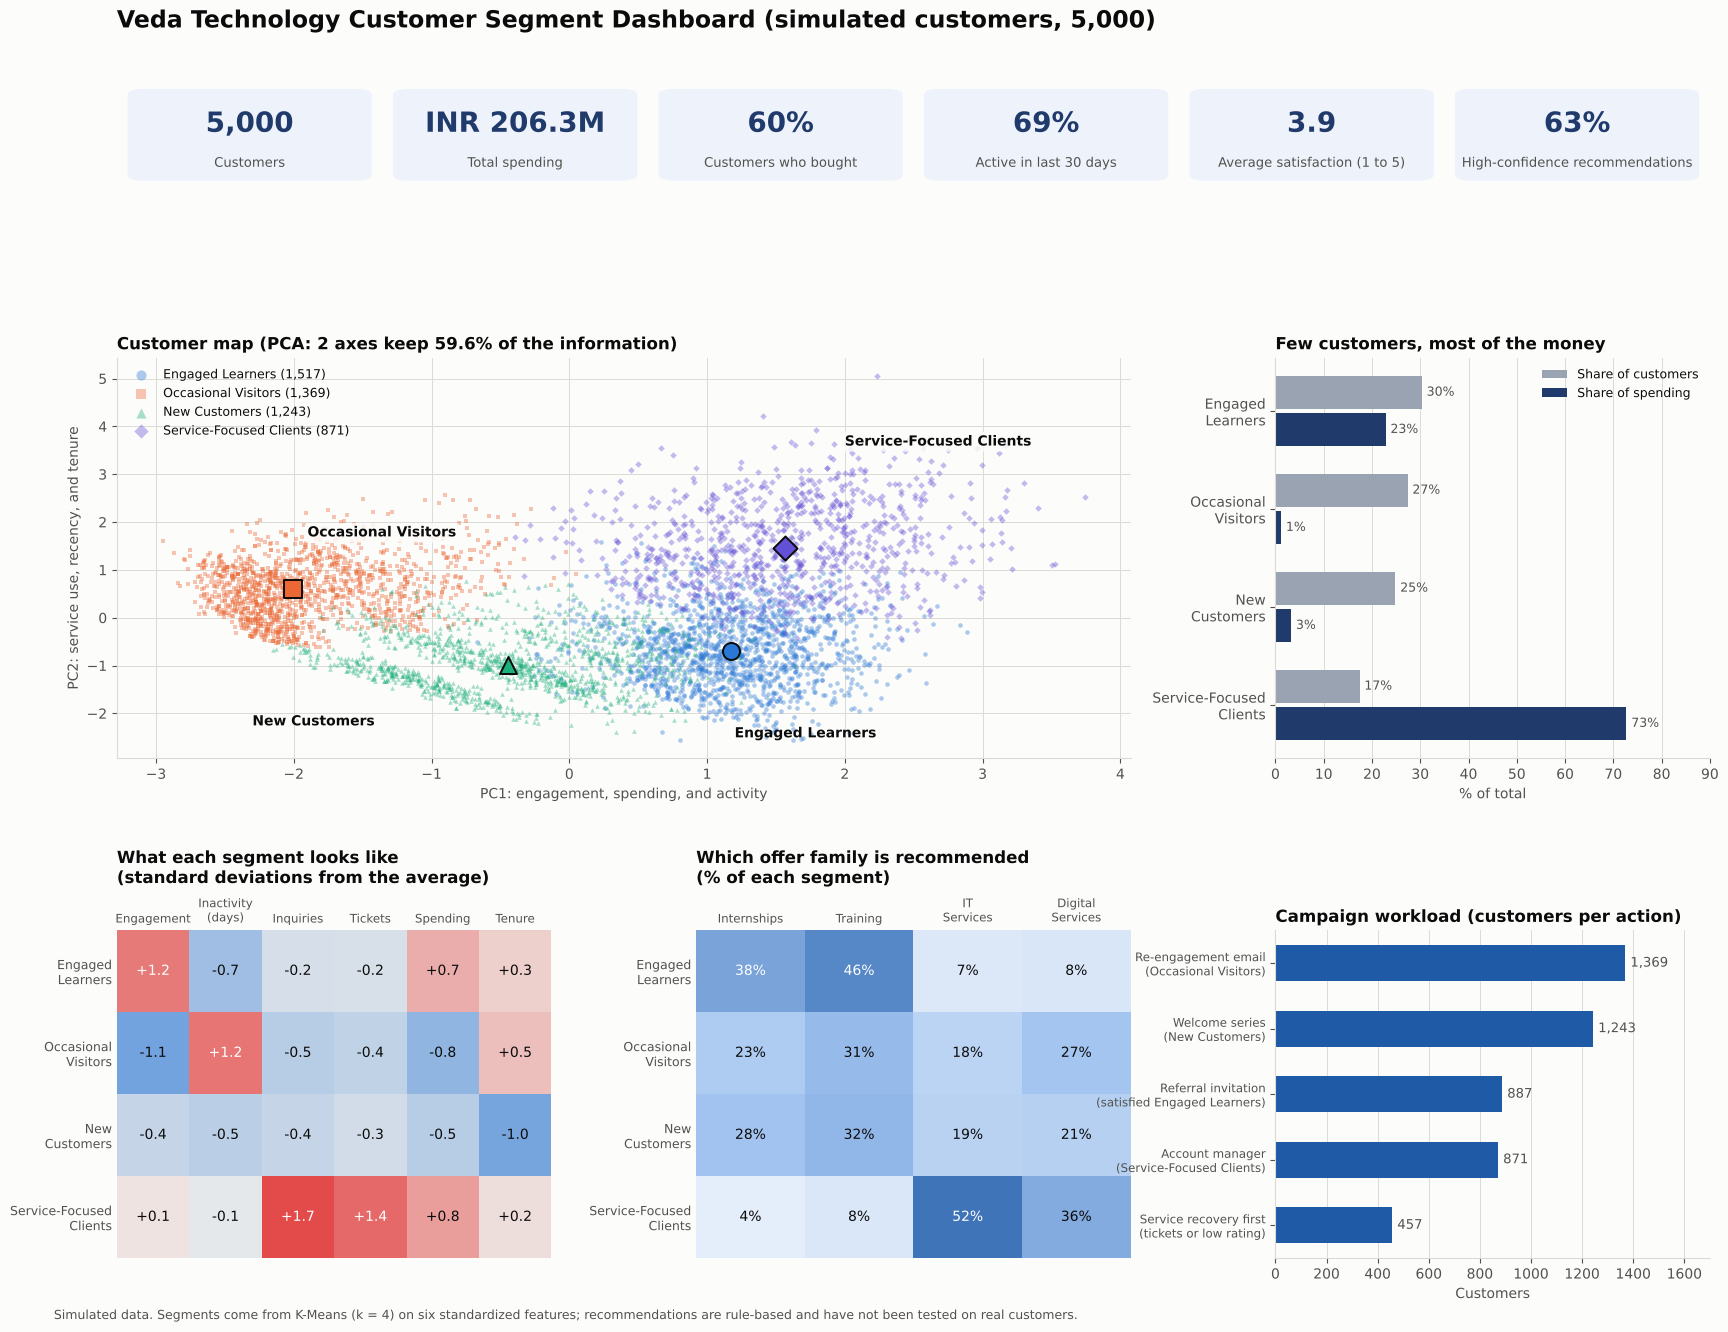

In [4]:
SEG_COLORS = {"Engaged Learners": "#2a78d6", "Occasional Visitors": "#eb6834", "New Customers": "#1baf7a", "Service-Focused Clients": "#6250d6"}
SEG_MARKERS = {"Engaged Learners": "o", "Occasional Visitors": "s", "New Customers": "^", "Service-Focused Clients": "D"}
INK, INK_SOFT, GRID, SURFACE = "#0b0b0b", "#52514e", "#dcdad4", "#fcfcfb"
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#f0f5fc", "#9cc0ee", "#1f5aa6"])
DIV = LinearSegmentedColormap.from_list("div_blue_red", ["#2a78d6", "#f0efec", "#e34948"])

plt.rcParams.update({"font.family": "DejaVu Sans", "axes.edgecolor": GRID, "axes.labelcolor": INK_SOFT, "xtick.color": INK_SOFT,
                     "ytick.color": INK_SOFT, "text.color": INK, "axes.titlecolor": INK, "axes.titlesize": 12, "axes.titleweight": "bold",
                     "axes.titlelocation": "left", "figure.facecolor": SURFACE, "axes.facecolor": SURFACE})
SHORT = {"Engaged Learners": "Engaged\nLearners", "Occasional Visitors": "Occasional\nVisitors", "New Customers": "New\nCustomers",
         "Service-Focused Clients": "Service-Focused\nClients"}


def clean_axes(ax, grid_axis=None):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    if grid_axis:
        ax.grid(axis=grid_axis, color=GRID, linewidth=0.7)
        ax.set_axisbelow(True)


fig = plt.figure(figsize=(18, 13.5))
grid = fig.add_gridspec(3, 6, height_ratios=[0.42, 1.65, 1.35], hspace=0.62, wspace=1.0, left=0.085, right=0.97, top=0.93, bottom=0.06)
fig.suptitle("Veda Technology Customer Segment Dashboard (simulated customers, 5,000)", fontsize=17, fontweight="bold", x=0.085, ha="left", y=0.985)

# KPI tiles (one strip, six equal tiles)
ax = fig.add_subplot(grid[0, :])
ax.axis("off")
ax.set_xlim(0, 6)
ax.set_ylim(0, 1)
for i, (label, value) in enumerate(kpis.items()):
    ax.add_patch(FancyBboxPatch((i + 0.04, 0.05), 0.92, 0.9, boxstyle="round,pad=0,rounding_size=0.06", facecolor="#eef3fb", edgecolor="none"))
    ax.text(i + 0.5, 0.60, value, ha="center", va="center", fontsize=20, fontweight="bold", color="#1f3a6b")
    ax.text(i + 0.5, 0.22, label, ha="center", va="center", fontsize=9.5, color=INK_SOFT)

# A: the 2D map
ax = fig.add_subplot(grid[1, :4])
for seg in SEGMENTS:
    rows = data["segment"] == seg
    ax.scatter(data.loc[rows, "pc1"], data.loc[rows, "pc2"], s=11, alpha=0.38, color=SEG_COLORS[seg], marker=SEG_MARKERS[seg],
               label=f"{seg} ({rows.sum():,})", linewidths=0)
    cx, cy = data.loc[rows, "pc1"].median(), data.loc[rows, "pc2"].median()
    ax.scatter(cx, cy, s=150, marker=SEG_MARKERS[seg], color=SEG_COLORS[seg], edgecolor=INK, linewidth=1.4, zorder=3)
ax.annotate("Occasional Visitors", (-1.9, 1.7), fontsize=10, color=INK, fontweight="bold", bbox=dict(boxstyle="round,pad=0.2", facecolor=SURFACE, edgecolor="none", alpha=0.85))
ax.annotate("New Customers", (-2.3, -2.25), fontsize=10, color=INK, fontweight="bold")
ax.annotate("Engaged Learners", (1.2, -2.5), fontsize=10, color=INK, fontweight="bold")
ax.annotate("Service-Focused Clients", (2.0, 3.6), fontsize=10, color=INK, fontweight="bold", bbox=dict(boxstyle="round,pad=0.2", facecolor=SURFACE, edgecolor="none", alpha=0.85))
ax.set_title("Customer map (PCA: 2 axes keep 59.6% of the information)")
ax.set_xlabel("PC1: engagement, spending, and activity")
ax.set_ylabel("PC2: service use, recency, and tenure")
ax.legend(loc="upper left", markerscale=2.2, frameon=False, fontsize=9)
clean_axes(ax, "both")

# B: share of customers vs. share of spending
ax = fig.add_subplot(grid[1, 4:])
share_c = (data["segment"].value_counts(normalize=True) * 100).reindex(SEGMENTS)
share_s = (data.groupby("segment")["total_spend_inr"].sum() / data["total_spend_inr"].sum() * 100).reindex(SEGMENTS)
y = np.arange(len(SEGMENTS))
ax.barh(y - 0.19, share_c, height=0.34, color="#9aa3b2", label="Share of customers")
ax.barh(y + 0.19, share_s, height=0.34, color="#1f3a6b", label="Share of spending")
for yi, a, b in zip(y, share_c, share_s):
    ax.text(a + 1, yi - 0.19, f"{a:.0f}%", va="center", fontsize=9, color=INK_SOFT)
    ax.text(b + 1, yi + 0.19, f"{b:.0f}%", va="center", fontsize=9, color=INK_SOFT)
ax.set_yticks(y)
ax.set_yticklabels([SHORT[s] for s in SEGMENTS])
ax.invert_yaxis()
ax.set_xlim(0, 90)
ax.set_xlabel("% of total")
ax.set_title("Few customers, most of the money")
ax.legend(loc="upper right", frameon=False, fontsize=9)
clean_axes(ax, "x")

# C: segment profile heatmap (standardized centers)
ax = fig.add_subplot(grid[2, :2])
z_cols = [c for c in features.columns if c.startswith("z_")]
z_labels = ["Engagement", "Inactivity\n(days)", "Inquiries", "Tickets", "Spending", "Tenure"]
centers = customers.merge(features[["customer_id"] + z_cols], on="customer_id").groupby("segment")[z_cols].mean().reindex(SEGMENTS)
ax.imshow(centers.values, cmap=DIV, vmin=-1.7, vmax=1.7, aspect="auto")
for i in range(centers.shape[0]):
    for j in range(centers.shape[1]):
        v = centers.values[i, j]
        ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=10, color="white" if abs(v) > 1.1 else INK)
ax.set_xticks(range(len(z_labels)))
ax.set_xticklabels(z_labels, fontsize=8.5)
ax.xaxis.tick_top()
ax.set_yticks(range(len(SEGMENTS)))
ax.set_yticklabels([SHORT[s] for s in SEGMENTS], fontsize=9)
ax.tick_params(length=0)
ax.set_title("What each segment looks like\n(standard deviations from the average)", pad=34)
for side in ax.spines.values():
    side.set_visible(False)

# D: recommended primary offer family by segment
ax = fig.add_subplot(grid[2, 2:4])
mix = (pd.crosstab(data["segment"], data["primary_family"], normalize="index") * 100).reindex(SEGMENTS)[["Internship Programs", "Training Programs", "IT Services", "Digital Services"]]
ax.imshow(mix.values, cmap=SEQ, vmin=0, vmax=60, aspect="auto")
for i in range(mix.shape[0]):
    for j in range(mix.shape[1]):
        v = mix.values[i, j]
        ax.text(j, i, f"{v:.0f}%", ha="center", va="center", fontsize=10, color="white" if v > 36 else INK)
ax.set_xticks(range(4))
ax.set_xticklabels(["Internships", "Training", "IT\nServices", "Digital\nServices"], fontsize=8.5)
ax.xaxis.tick_top()
ax.set_yticks(range(len(SEGMENTS)))
ax.set_yticklabels([SHORT[s] for s in SEGMENTS], fontsize=9)
ax.tick_params(length=0)
ax.set_title("Which offer family is recommended\n(% of each segment)", pad=34)
for side in ax.spines.values():
    side.set_visible(False)

# E: campaign workload
ax = fig.add_subplot(grid[2, 4:])
workload = pd.Series({
    "Re-engagement email\n(Occasional Visitors)": (data["segment"] == "Occasional Visitors").sum(),
    "Welcome series\n(New Customers)": (data["segment"] == "New Customers").sum(),
    "Referral invitation\n(satisfied Engaged Learners)": data["rules_applied"].str.contains("R6").sum(),
    "Account manager\n(Service-Focused Clients)": (data["segment"] == "Service-Focused Clients").sum(),
    "Service recovery first\n(tickets or low rating)": data["rules_applied"].str.contains("R5").sum(),
}).sort_values()
ax.barh(workload.index, workload.values, height=0.55, color="#1f5aa6")
for yi, v in enumerate(workload.values):
    ax.text(v + 20, yi, f"{v:,}", va="center", fontsize=9.5, color=INK_SOFT)
ax.set_xlim(0, 1700)
ax.set_xlabel("Customers")
ax.set_title("Campaign workload (customers per action)")
ax.tick_params(axis="y", labelsize=8.5)
clean_axes(ax, "x")

fig.text(0.05, 0.015, "Simulated data. Segments come from K-Means (k = 4) on six standardized features; recommendations are rule-based and have not been tested on real customers.",
         fontsize=9, color=INK_SOFT)
fig.savefig("customer_segment_dashboard.png", dpi=130, facecolor=SURFACE)
plt.show()

**Observation:** The dashboard answers four questions on one page. **How big is the business?** 5,000 customers and INR 206.3 million in spending, of whom 60% have bought, 69% were active in the last 30 days, and the average satisfaction is 3.9 (counting only the customers who answered the survey). **Where is the money?** The Service-Focused Clients are 17% of the customers but 73% of the spending, while the Occasional Visitors are 27% of the customers and 1% of the spending. **Who are the segments?** The heatmap shows what makes each one different: the Engaged Learners are far above average in engagement (+1.2) and spending (+0.7), the Occasional Visitors are the least engaged (-1.1) and the most inactive (+1.2), the New Customers are defined by a short tenure (-1.0), and the Service-Focused Clients stand out in inquiries (+1.7) and tickets (+1.4). **What should be done?** 88% of the Service-Focused Clients are pointed to IT or digital services, and 84% of the Engaged Learners to training or internships. The workload chart shows that the largest campaigns are the re-engagement email (1,369 customers) and the welcome series (1,243), and the smallest and most valuable action is service recovery (457 customers).

## 4. Business Recommendations

Each recommendation has the evidence from the project, a concrete action, and an impact that
is labeled as a scenario with its assumptions. The figures are calculated below from the saved
tables, so the recommendations can be traced back to the data.

**The evidence figures**

In [5]:
total_spend = data["total_spend_inr"].sum()
seg = {name: data[data["segment"] == name] for name in SEGMENTS}
sf, nc, ov, el = (seg[n] for n in ["Service-Focused Clients", "New Customers", "Occasional Visitors", "Engaged Learners"])

at_risk = sf[(sf["support_tickets"] >= 3) | (sf["satisfaction_rating"] <= 2)]
nc_non_buyers = int((~nc["is_buyer"]).sum())
ov_non_buyers = int((~ov["is_buyer"]).sum())
referrers = int(data["rules_applied"].str.contains("R6").sum())
by_channel = data.groupby("acquisition_channel").agg(customers=("customer_id", "count"), buyers_pct=("is_buyer", "mean"), median_spend_inr=("total_spend_inr", "median"))
by_channel["buyers_pct"] *= 100

ev = {
    "sf_customers": len(sf), "sf_share_customers": len(sf) / len(data) * 100, "sf_share_spend": sf["total_spend_inr"].sum() / total_spend * 100,
    "at_risk_n": len(at_risk), "at_risk_pct_of_sf": len(at_risk) / len(sf) * 100, "at_risk_spend": at_risk["total_spend_inr"].sum(),
    "at_risk_share_total": at_risk["total_spend_inr"].sum() / total_spend * 100,
    "sf_sat_many_tickets": sf.loc[sf["support_tickets"] >= 3, "satisfaction_rating"].mean(), "sf_sat_few_tickets": sf.loc[sf["support_tickets"] < 3, "satisfaction_rating"].mean(),
    "nc_n": len(nc), "nc_non_buyers": nc_non_buyers, "nc_non_buyers_pct": nc_non_buyers / len(nc) * 100,
    "nc_buyer_median_spend": nc.loc[nc["is_buyer"], "total_spend_inr"].median(),
    "ov_n": len(ov), "ov_non_buyers": ov_non_buyers, "ov_inactive_60_pct": (ov["days_since_last_activity"] > 60).mean() * 100,
    "ov_buyer_median_spend": ov.loc[ov["is_buyer"], "total_spend_inr"].median(),
    "referrers": referrers, "referrers_pct_of_el": referrers / len(el) * 100,
    "referral_buyers_pct": by_channel.loc["Referral", "buyers_pct"], "referral_median": by_channel.loc["Referral", "median_spend_inr"],
    "email_buyers_pct": by_channel.loc["Email", "buyers_pct"], "paid_buyers_pct": by_channel.loc["Paid Ads", "buyers_pct"],
    "paid_median": by_channel.loc["Paid Ads", "median_spend_inr"], "social_buyers_pct": by_channel.loc["Social Media", "buyers_pct"],
    "social_median": by_channel.loc["Social Media", "median_spend_inr"],
    "paid_social_share_ov_nc": data[data["segment"].isin(["Occasional Visitors", "New Customers"])]["acquisition_channel"].isin(["Paid Ads", "Social Media"]).mean() * 100,
    "el_n": len(el), "el_buyers_pct": el["is_buyer"].mean() * 100, "el_median_aov": el.loc[el["is_buyer"], "avg_order_value_inr"].median(), "el_avg_purchases": el["purchases"].mean(),
    "survey_missing_pct": data["satisfaction_rating"].isna().mean() * 100,
    "ov_response_pct": ov["satisfaction_rating"].notna().mean() * 100, "nc_response_pct": nc["satisfaction_rating"].notna().mean() * 100,
    "low_conf_sf_pct": (sf["confidence"] == "Low").mean() * 100, "high_conf_pct": (data["confidence"] == "High").mean() * 100,
}
pd.Series(ev, name="value").round(1).to_frame()

,value
sf_customers,871.0
sf_share_customers,17.4
sf_share_spend,72.7
at_risk_n,343.0
at_risk_pct_of_sf,39.4
at_risk_spend,63186900.0
at_risk_share_total,30.6
sf_sat_many_tickets,3.2
sf_sat_few_tickets,3.8
nc_n,1243.0


**Scenario calculations**

Each scenario is a simple multiplication with an assumption that is stated openly. They are
meant to show the size of the opportunity, not to forecast it.

In [6]:
scenario = {
    # 10% of the at-risk Service-Focused spending lost, if nothing is done
    "risk_10pct": ev["at_risk_spend"] * 0.10,
    # 10% of the New Customers who have not bought make a first purchase at the median first-purchase spend
    "first_purchase": round(ev["nc_non_buyers"] * 0.10) * ev["nc_buyer_median_spend"],
    "first_purchase_n": round(ev["nc_non_buyers"] * 0.10),
    # 10% of the Occasional Visitors who never bought buy once at the median spend of their buyers
    "reactivation": round(ev["ov_non_buyers"] * 0.10) * ev["ov_buyer_median_spend"],
    "reactivation_n": round(ev["ov_non_buyers"] * 0.10),
    # 5% of the satisfied Engaged Learners refer one customer who spends like the median Referral customer
    "referral_n": round(ev["referrers"] * 0.05),
    "referral": round(ev["referrers"] * 0.05) * ev["referral_median"],
    # 10% of the Engaged Learners buy one more program at their median order value
    "upsell_n": round(ev["el_n"] * 0.10),
    "upsell": round(ev["el_n"] * 0.10) * ev["el_median_aov"],
}
pd.Series(scenario, name="value").round(0).to_frame()

,value
risk_10pct,6318690.0
first_purchase,451400.0
first_purchase_n,74.0
reactivation,530000.0
reactivation_n,106.0
referral_n,44.0
referral,792000.0
upsell_n,152.0
upsell,1394600.0


In [7]:
def inr_m(x):
    return f"INR {x / 1e6:.1f} million" if x >= 1e6 else f"INR {x / 1e6:.2f} million"


rows = [
    ("High", "Service-Focused Clients",
     f"The {ev['sf_customers']} Service-Focused Clients are {ev['sf_share_customers']:.0f}% of customers but {ev['sf_share_spend']:.1f}% of spending. {ev['at_risk_n']} of them ({ev['at_risk_pct_of_sf']:.0f}%) have 3 or more support tickets or a rating of 2 or less, and hold {inr_m(ev['at_risk_spend'])} ({ev['at_risk_share_total']:.1f}% of all spending). Those with many tickets rate their experience lower ({ev['sf_sat_many_tickets']:.1f} versus {ev['sf_sat_few_tickets']:.1f}).",
     "Start service recovery with the customers flagged by rule R5 (resolve the open tickets and contact the customer personally), assign an account manager to every Service-Focused Client, and keep the 4-hour first-response target from the Day 38 analysis.",
     f"Losing 10% of the at-risk spending would cost about {inr_m(scenario['risk_10pct'])}, more than the revenue added in any of the scenarios below."),
    ("High", "Engaged Learners",
     f"Engaged Learners have made {ev['el_avg_purchases']:.1f} purchases on average, with a median order value of INR {ev['el_median_aov']:,.0f} among buyers, and rules R2 and R3 give each of them a cross-sell in the neighboring family (training to internship and the reverse).",
     "Offer the cross-sell as part of a learning path (for example a training program followed by the matching internship) and test it on a share of the segment first.",
     f"If 10% of the segment ({scenario['upsell_n']} customers) bought one more program at the median order value, that would add about {inr_m(scenario['upsell'])}."),
    ("High", "Engaged Learners",
     f"The {ev['el_n']:,} Engaged Learners are the healthiest group ({ev['el_buyers_pct']:.0f}% have bought, highest satisfaction), and {ev['referrers']} of them rated Veda Technology 4 or 5. Customers who came through Referral or Email buy more often ({ev['referral_buyers_pct']:.1f}% for Referral and {ev['email_buyers_pct']:.1f}% for Email) than those from Paid Ads ({ev['paid_buyers_pct']:.0f}%), with a median spending of INR {ev['referral_median']:,.0f} for Referral against INR {ev['paid_median']:,.0f} for Paid Ads.",
     "Invite the satisfied Engaged Learners to a referral program (rule R6), and track how many new customers each invitation brings.",
     f"If 5% of the {ev['referrers']} invited customers brought one new customer who spends like the median Referral customer, that would add {scenario['referral_n']} customers and about {inr_m(scenario['referral'])}."),
    ("Medium", "New Customers",
     f"{ev['nc_non_buyers']} of the {ev['nc_n']:,} New Customers ({ev['nc_non_buyers_pct']:.0f}%) have not bought yet, and they signed up about a month ago on average, so they are still reachable.",
     "Run a welcome series that introduces the recommended offer of each customer (rules R1 to R3) and aims at the first purchase, with a small incentive such as a free trial session for training programs.",
     f"If 10% of them ({scenario['first_purchase_n']} customers) made a first purchase at the median spend of current New Customer buyers (INR {ev['nc_buyer_median_spend']:,.0f}), that would add about {inr_m(scenario['first_purchase'])}."),
    ("Medium", "Occasional Visitors",
     f"{ev['ov_n']:,} customers ({ev['ov_inactive_60_pct']:.0f}% inactive for more than 60 days) are Occasional Visitors, and {ev['ov_non_buyers']:,} of them have never bought. They hold only 1.2% of spending, so the effort per customer should stay low.",
     "Send a low-cost re-engagement email that features the recommended offer for the customer's interest, and stop contacting customers who do not respond after two emails.",
     f"If 10% of the customers who never bought ({scenario['reactivation_n']}) bought once at the median spend of the segment's buyers (INR {ev['ov_buyer_median_spend']:,.0f}), that would add about {inr_m(scenario['reactivation'])}."),
    ("Medium", "Marketing",
     f"Paid Ads and Social Media bring {ev['paid_social_share_ov_nc']:.0f}% of the Occasional Visitors and New Customers, and those channels have the lowest share of buyers ({ev['paid_buyers_pct']:.0f}% and {ev['social_buyers_pct']:.0f}%, against {ev['referral_buyers_pct']:.0f}% for Referral) and the lowest median spending (INR {ev['paid_median']:,.0f} and INR {ev['social_median']:,.0f}). This agrees with the Day 38 finding that these channels cost the most per lead.",
     "Move part of the Paid Ads and Social Media budget to Referral and Email, and track the segment of each new customer, so channels are judged by the segments they bring and not only by the number of leads.",
     "Not calculated separately, because the budget effect is already estimated on Day 38 (about 3,540 more leads a year in the upper scenario); test on a small budget first."),
    ("Medium", "Data and measurement",
     f"{ev['survey_missing_pct']:.0f}% of the customers have no satisfaction rating, and only {ev['ov_response_pct']:.0f}% of the Occasional Visitors and {ev['nc_response_pct']:.0f}% of the New Customers answered. The interest is recorded only at the level of the offer family, and there is no record of the offers customers accepted. {ev['low_conf_sf_pct']:.0f}% of the Service-Focused Clients have a Low confidence recommendation.",
     "Send a short survey after each purchase or ticket, record the offer each customer viewed and accepted, and record the interest at the level of the individual program or service.",
     "Makes it possible to score the recommendations and to personalize the offer inside each family."),
    ("Foundation", "Validation",
     "The customers are simulated with four built-in patterns, the clusters overlap (average silhouette 0.29), and the recommendation rules are design choices that were never tested on real customers.",
     "Replace the simulated data with real customer records, test each recommendation in a controlled campaign (send the recommended offer to half of a segment and compare responses), and re-run the clustering every quarter, checking that the segments stay stable.",
     "Turns these scenarios into measured results."),
]
recommendations = pd.DataFrame(rows, columns=["priority", "segment_or_area", "evidence", "recommendation", "estimated_impact"])
recommendations.to_csv("business_recommendations.csv", index=False)

print("Saved: business_recommendations.csv | recommendations:", len(recommendations))
recommendations[["priority", "segment_or_area", "recommendation", "estimated_impact"]]

Saved: business_recommendations.csv | recommendations: 8


,priority,segment_or_area,recommendation,estimated_impact
0,High,Service-Focused Clients,"Start service recovery with the customers flagged by rule R5 (resolve the open tickets and contact the customer personally), assign an account manager to every Service-Focused Client, and keep the...","Losing 10% of the at-risk spending would cost about INR 6.3 million, more than the revenue added in any of the scenarios below."
1,High,Engaged Learners,Offer the cross-sell as part of a learning path (for example a training program followed by the matching internship) and test it on a share of the segment first.,"If 10% of the segment (152 customers) bought one more program at the median order value, that would add about INR 1.4 million."
2,High,Engaged Learners,"Invite the satisfied Engaged Learners to a referral program (rule R6), and track how many new customers each invitation brings.","If 5% of the 887 invited customers brought one new customer who spends like the median Referral customer, that would add 44 customers and about INR 0.79 million."
3,Medium,New Customers,"Run a welcome series that introduces the recommended offer of each customer (rules R1 to R3) and aims at the first purchase, with a small incentive such as a free trial session for training programs.","If 10% of them (74 customers) made a first purchase at the median spend of current New Customer buyers (INR 6,100), that would add about INR 0.45 million."
4,Medium,Occasional Visitors,"Send a low-cost re-engagement email that features the recommended offer for the customer's interest, and stop contacting customers who do not respond after two emails.","If 10% of the customers who never bought (106) bought once at the median spend of the segment's buyers (INR 5,000), that would add about INR 0.53 million."
5,Medium,Marketing,"Move part of the Paid Ads and Social Media budget to Referral and Email, and track the segment of each new customer, so channels are judged by the segments they bring and not only by the number of...","Not calculated separately, because the budget effect is already estimated on Day 38 (about 3,540 more leads a year in the upper scenario); test on a small budget first."
6,Medium,Data and measurement,"Send a short survey after each purchase or ticket, record the offer each customer viewed and accepted, and record the interest at the level of the individual program or service.",Makes it possible to score the recommendations and to personalize the offer inside each family.
7,Foundation,Validation,"Replace the simulated data with real customer records, test each recommendation in a controlled campaign (send the recommended offer to half of a segment and compare responses), and re-run the clu...",Turns these scenarios into measured results.


**Observation:** The project ends with eight recommendations, three of high priority, four of medium priority, and one foundation item, ranked by the value at stake and the strength of the evidence. The largest number by far is the money at risk among the Service-Focused Clients: 343 customers with many tickets or a low rating hold INR 63.2 million (30.6% of all spending), so losing even 10% of it (INR 6.3 million) would cost more than all the growth scenarios combined, which add INR 0.45 to 1.39 million each. The growth scenarios are small because they assume modest changes (10% of a group making one purchase, or 5% of satisfied customers referring one person) at the median spending, and they are placed in the file with their assumptions so a manager can change them. The two scenarios are not directly comparable, because one is a loss avoided and the others are revenue added. The recommendation about marketing channels agrees with the Day 38 analysis, but the two datasets were simulated separately, so the agreement is consistent without being independent confirmation from real customers.

## 5. Streamlit App

The interactive version of the dashboard is the file `app.py` in this folder. It reads the same
tables from `datasets/veda_customers/segments/` and lets the user filter the customers by segment,
customer type, interest, and region, see the segment profiles and the customer map, and look up the
recommendation for a single customer. It is started from this folder with:

```
pip install streamlit pandas altair
streamlit run app.py
```

The check below makes sure that the tables the app needs have the columns it uses, and that the
app's numbers match the notebook.

In [8]:
APP_COLUMNS = ["customer_id", "segment", "customer_type", "primary_interest", "region", "acquisition_channel", "total_spend_inr", "pc1", "pc2", "satisfaction_rating"]
REC_COLUMNS = ["customer_id", "primary_offer", "cross_sell_offer", "action", "confidence", "reason", "rules_applied"]

print("Segmented table has the columns of the app:", all(c in customers.columns for c in APP_COLUMNS))
print("Recommendation table has the columns of the app:", all(c in pd.read_csv(SEGMENT_DIR / "service_recommendations.csv").columns for c in REC_COLUMNS))
print("Customer IDs match one to one:", set(customers["customer_id"]) == set(recs["customer_id"]) and customers["customer_id"].is_unique)

Segmented table has the columns of the app: True
Recommendation table has the columns of the app: True


Customer IDs match one to one: True


## Outcome

By the end of this task, the project was complete: an interactive customer segment dashboard (`app.py`, a Streamlit app with filters, a customer map, segment profiles, recommendations, and a customer lookup), a static dashboard picture, eight business recommendations with evidence and scenarios, and a final report. The dashboard shows that the 5,000 simulated customers fall into four segments of very different value: the 871 Service-Focused Clients (17% of customers) hold 72.7% of the INR 206.3 million in spending, and 343 of them, holding INR 63.2 million (30.6% of all spending), have many tickets or a low rating, so protecting them is the first priority. The next priorities are the cross-sell and referral program for the 1,517 Engaged Learners, a welcome series that turns 738 New Customers into buyers, and a low-cost re-engagement email for the Occasional Visitors. The impact figures are scenarios with stated assumptions and not forecasts, the data is simulated, the segments overlap (average silhouette 0.29), and the recommendations have never been tested on real customers, so the first step is a controlled test, such as sending the recommended offer to half of a segment. The main lesson was that a segmentation is only useful when it ends in actions: the segments became a list of customers per campaign (for example 457 for service recovery and 887 for the referral invitation), and the honest limits had to travel with them.